# Setup

In [1]:
library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

#install.packages("pROC")
#library(pROC)
install.packages("pheatmap")
library(pheatmap)
install.packages("binom")
library(binom)

#install.packages("networkD3")
#library(networkD3)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}


Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.2.1     ✔ readr   2.2.0
✔ forcats 1.0.1     ✔ stringr 1.6.0
✔ ggplot2 4.0.2     ✔ tibble  3.3.1
✔ purrr   1.2.1     ✔ tidyr   1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

## Load and merge data

In [2]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file)

#MERGE
demo_sdoh<-merge(demo, ses_data, on="person_id", how="inner")

#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(PRS, case_control, on="person_id", how="left")
merged_data_0<-merge(merged_data, demo_sdoh, on="person_id", how="left")

dim(merged_data)

#Load PsRS data 
PsRS_file = paste0(current_directory, "/data/individual_PsRS_OOF.csv")
PsRS  <- read_csv(PsRS_file)

#MERGE
merged_data<-merge(merged_data_0, PsRS, on="person_id", how="left")
colnames(merged_data)

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 135557 Columns: 9
── Column specification ────────────────────

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 135033     18

Rows: 104438 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): person_id, Asthma_PsRS, Afib_PsRS, BreastC_PsRS, CKD_PsRS, CHD_PsRS...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "person_id"                         "Asthma_adjusted_score"            
 [3] "Afib_adjusted_score"               "BreastC_adjusted_score"           
 [5] "CKD_adjusted_score"                "CHD_adjusted_score"               
 [7] "ProstateC_adjusted_score"          "t1d_adjusted_score"               
 [9] "t2d_adjusted_score"                "Asthma"                           
[11] "Afib"                              "BreastC"                          
[13] "CKD"                               "CHD"                              
[15] "HyperC"                            "ProstateC"                        
[17] "t2d"                               "t1d"                              
[19] "date_of_birth"                     "AIAN"                             
[21] "Asian"                             "Black"                            
[23] "Mid"                               "Multiple"                         
[25] "PI"                                "White"                            
[27] "His"                               "race_unknown"                     
[29] "SexGender"                         "age_today"                        
[31] "ancestry_pred"                     "PC_1"                             
[33] "PC_2"                              "PC_3"                             
[35] "PC_4"                              "PC_5"                             
[37] "PC_6"                              "PC_7"                             
[39] "PC_8"                              "PC_9"                             
[41] "PC_10"                             "PC_11"                            
[43] "PC_12"                             "PC_13"                            
[45] "PC_14"                             "PC_15"                            
[47] "PC_16"                             "number_living"                    
[49] "where_born"                        "military"                         
[51] "healthcare"                        "disabled"                         
[53] "sexual_orientation"                "LGBTQIA"                          
[55] "basics_survey_datetime"            "income_grouped"                   
[57] "min_date"                          "max_date"                         
[59] "ehr_length"                        "relative_health"                  
[61] "record_depth"                      "visit_frequency"                  
[63] "age"                               "record_depth_winsorized"          
[65] "visit_frequency_winsorized"        "age2"                             
[67] "income"                            "education"                        
[69] "per_poverty_threshold"             "individual_poverty"               
[71] "american_community_survey_year"    "fraction_assisted_income"         
[73] "fraction_no_high_school_education" "lower_median_income"              
[75] "fraction_no_health_insurance"      "fraction_poverty"                 
[77] "fraction_vacant_housing"           "deprivation_index"                
[79] "Asthma_PsRS"                       "Afib_PsRS"                        
[81] "BreastC_PsRS"                      "CKD_PsRS"                         
[83] "CHD_PsRS"                          "ProstateC_PsRS"                   
[85] "t2d_PsRS"                          "t1d_PsRS"

In [3]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

## Set up lists

In [4]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")


disease_name_mapping <- c(
  "Asthma" = "Asthma",
    "Afib" = "Atrial Fibrilation (Afib)",
    "BreastC" = "Breast Cancer",
    "CKD" = "Chronic Kidney Disease (CKD)", 
    "CHD" = "Coronary Heart Disease (CHD)",
    "ProstateC" = "Prostate Cancer", 
  "t2d" = "Type 2 Diabetes (T2D)",
  "t1d" = "Type 1 Diabetes (T1D)"
)

disease_name_mapping_short <- c(
    "Afib" = "Afib",
    "CKD" = "CKD", 
    "CHD" = "CHD",
  "t2d" = "T2D",
  "t1d" = "T1D",
    "BreastC" = "Breast\nCancer",
    "ProstateC" = "Prostate\nCancer"
)

facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

## Min-max normalize for comparability

In [5]:
merged_data <- merged_data %>%
  mutate(
    across(
      matches("(_adjusted_score|_PsRS)$"),   # columns ending with either pattern
      ~ (.-min(., na.rm = TRUE)) / (max(., na.rm = TRUE) - min(., na.rm = TRUE))
    )
  )


## Make Genetic Risk Quantiles

In [6]:
merged_data <- merged_data %>%
  mutate(
    across(
      ends_with("_adjusted_score"),
      ~ ntile(.x, 10),
      .names = "{sub('_adjusted_score$', '', .col)}_quantiles"
    )
  )


## Of those top 10% genetic risk, how much of that explained by SDoH?

In [7]:
plot_df <- map_dfr(diseases, function(disease) {

  q_col    <- paste0(disease, "_quantiles")
  psrs_col <- paste0(disease, "_PsRS")

  base <- merged_data %>%
    filter(.data[[q_col]] == 10) %>%
    mutate(PsRS_q = ntile(.data[[psrs_col]], 5))

  summarize_group <- function(df, label) {
    df %>%
      summarise(
        cases = sum(.data[[disease]] == 1, na.rm = TRUE),
        n     = sum(!is.na(.data[[disease]])),
        prevalence = round(cases / n,4), 
      ) %>%
      mutate(
        ci = binom.confint(cases, n, method = "wilson"),
        lower = round(ci$lower, 3),
        upper = round(ci$upper, 3), 
        disease = disease,
        PsRS_group = label
      ) %>%
      select(disease, PsRS_group, prevalence, lower, upper)
  }

  bind_rows(
    summarize_group(base %>% filter(PsRS_q == 1),      "Low PsRS (Q1)"),
    summarize_group(base %>% filter(PsRS_q %in% 2:4),  "Mid PsRS (Q2–Q4)"),
    summarize_group(base %>% filter(PsRS_q == 5),      "High PsRS (Q5)")
  )
})

plot_df_top_genetic_risk <- plot_df %>% mutate(disease = as.character(disease), 
                              disease = recode(disease, !!!disease_name_mapping_short, .default = disease) )


plot_df_top_genetic_risk <- plot_df_top_genetic_risk %>%
  mutate(
    disease = factor(disease, levels = facet_order),
    PsRS_group = factor(
      PsRS_group,
      levels = c("Low PsRS (Q1)", "Mid PsRS (Q2–Q4)", "High PsRS (Q5)")
    )
  )


plot_df_top_genetic_risk

disease,PsRS_group,prevalence,lower,upper
<fct>,<fct>,<dbl>,<dbl>,<dbl>
Asthma,Low PsRS (Q1),0.3420,0.307,0.379
Asthma,Mid PsRS (Q2–Q4),0.4765,0.454,0.499
Asthma,High PsRS (Q5),0.7066,0.670,0.740
Afib,Low PsRS (Q1),0.2380,0.205,0.275
Afib,Mid PsRS (Q2–Q4),0.4543,0.431,0.478
Afib,High PsRS (Q5),0.5445,0.503,0.585
Breast Cancer,Low PsRS (Q1),0.0602,0.049,0.074
Breast Cancer,Mid PsRS (Q2–Q4),0.1193,0.110,0.130
Breast Cancer,High PsRS (Q5),0.1738,0.154,0.195


In [8]:
# Filter for only Low and High PsRS groups
diff_table_top_genetic_risk <- plot_df %>%
  filter(PsRS_group %in% c("Low PsRS (Q1)", "High PsRS (Q5)")) %>%
  select(disease, PsRS_group, prevalence) %>%
  pivot_wider(
    names_from = PsRS_group,
    values_from = prevalence
  ) %>%
  mutate(
    percent_difference = round(100 * (`High PsRS (Q5)` - `Low PsRS (Q1)`) / `Low PsRS (Q1)`,2)
  ) %>%
  select(disease, `Low PsRS (Q1)`, `High PsRS (Q5)`, percent_difference)

diff_table_top_genetic_risk


disease,Low PsRS (Q1),High PsRS (Q5),percent_difference
<chr>,<dbl>,<dbl>,<dbl>
Asthma,0.3420,0.7066,106.61
Afib,0.2380,0.5445,128.78
BreastC,0.0602,0.1738,188.70
CKD,0.3342,0.3608,7.96
CHD,0.1713,0.2558,49.33
ProstateC,0.2984,0.8178,174.06
t2d,0.3964,0.6693,68.84
t1d,0.0350,0.0607,73.43


Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”


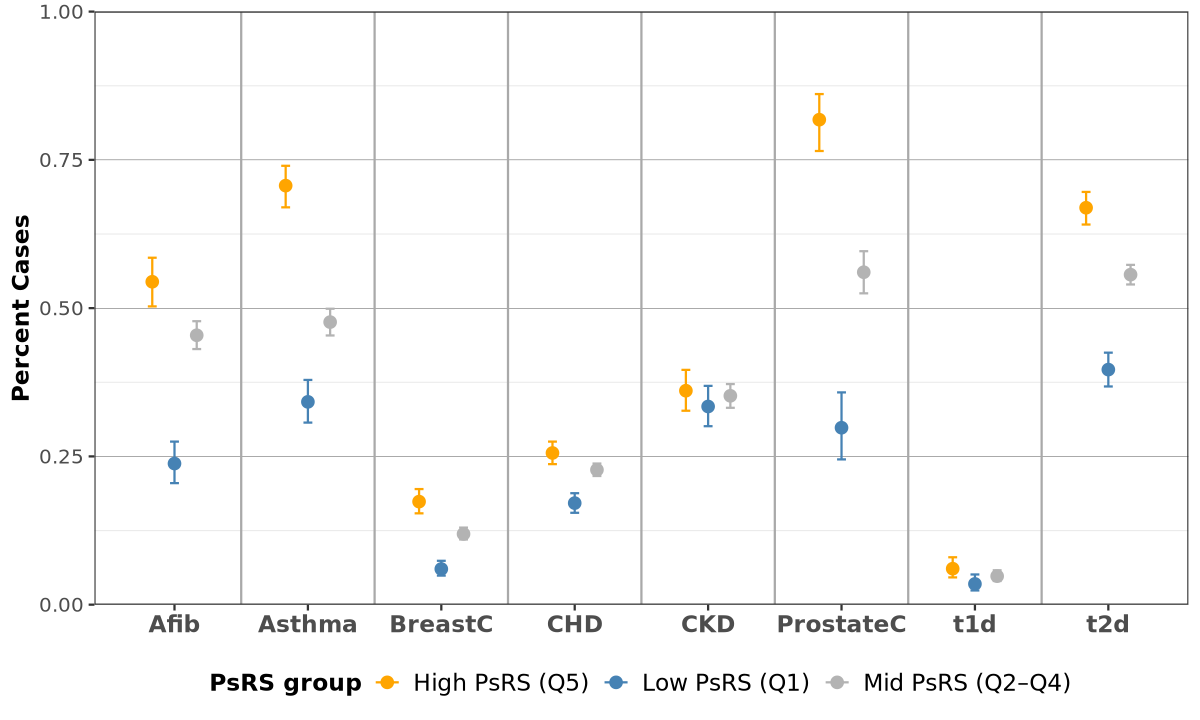

In [9]:
options(repr.plot.width = 10, repr.plot.height = 6)  # Set width and height

final_A_plot <- ggplot(plot_df, aes(
  x = disease,
  y = prevalence,
  color = PsRS_group
)) +
  geom_point(
    position = position_dodge(width = 0.5),
    size = 3
  ) +
  scale_y_continuous(
    limits = c(0, 1),
    expand = c(0, 0)
  ) +
  geom_errorbar(
    aes(ymin = lower, ymax = upper),
    position = position_dodge(width = 0.5),
    width = 0.2
  ) +
  scale_color_manual(
    values = c(
      "Low PsRS (Q1)" = "steelblue",   
      "Mid PsRS (Q2–Q4)" = "grey70", 
      "High PsRS (Q5)" = "orange"   
    )
  ) +
  theme(
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black"),
    axis.text.x = element_text(face="bold", size=14),
    axis.text.y = element_text(size=12),
    axis.title.y = element_text(face="bold", size=14),
    legend.title = element_text(face="bold", hjust = 0.5, size = 14),
    legend.text = element_text(size = 14),
    legend.position = "bottom",
    legend.box.spacing = unit(-5, "pt"),
  ) +
  labs(
    x = "",
    y = "Percent Cases",
    color = "PsRS group"
  ) +
  geom_vline(
    xintercept = seq(1.5, length(unique(plot_df$disease)) - 0.5, 1),
    color = "darkgrey"
  )


final_A_plot

## Of those bottom 10% genetic risk, how much of that explained by SDoH?

In [10]:
plot_df <- map_dfr(diseases, function(disease) {

  q_col    <- paste0(disease, "_quantiles")
  psrs_col <- paste0(disease, "_PsRS")

  base <- merged_data %>%
    filter(.data[[q_col]] == 1) %>%
    mutate(PsRS_q = ntile(.data[[psrs_col]], 5))

  summarize_group <- function(df, label) {
    df %>%
      summarise(
        cases = sum(.data[[disease]] == 1, na.rm = TRUE),
        n     = sum(!is.na(.data[[disease]])),
        prevalence = round(cases / n,4), 
      ) %>%
      mutate(
        ci = binom.confint(cases, n, method = "wilson"),
        lower = round(ci$lower, 3),
        upper = round(ci$upper, 3), 
        disease = disease,
        PsRS_group = label
      ) %>%
      select(disease, PsRS_group, prevalence, lower, upper)
  }

  bind_rows(
    summarize_group(base %>% filter(PsRS_q == 1),      "Low PsRS (Q1)"),
    summarize_group(base %>% filter(PsRS_q %in% 2:4),  "Mid PsRS (Q2–Q4)"),
    summarize_group(base %>% filter(PsRS_q == 5),      "High PsRS (Q5)")
  )
})

plot_df_bottom_genetic_risk <- plot_df %>% mutate(disease = as.character(disease), 
                              disease = recode(disease, !!!disease_name_mapping_short, .default = disease) )


plot_df_bottom_genetic_risk <- plot_df_bottom_genetic_risk %>%
  mutate(
    disease = factor(disease, levels = facet_order),
    PsRS_group = factor(
      PsRS_group,
      levels = c("Low PsRS (Q1)", "Mid PsRS (Q2–Q4)", "High PsRS (Q5)")
    )
  )


plot_df_bottom_genetic_risk

disease,PsRS_group,prevalence,lower,upper
<fct>,<fct>,<dbl>,<dbl>,<dbl>
Asthma,Low PsRS (Q1),0.1948,0.164,0.229
Asthma,Mid PsRS (Q2–Q4),0.3132,0.292,0.336
Asthma,High PsRS (Q5),0.4930,0.452,0.534
Afib,Low PsRS (Q1),0.1336,0.106,0.166
Afib,Mid PsRS (Q2–Q4),0.2676,0.246,0.291
Afib,High PsRS (Q5),0.2414,0.206,0.281
Breast Cancer,Low PsRS (Q1),0.0314,0.023,0.042
Breast Cancer,Mid PsRS (Q2–Q4),0.0471,0.041,0.054
Breast Cancer,High PsRS (Q5),0.0744,0.061,0.090


In [11]:
plot_df_bottom_genetic_risk$PRS_decile <- 1
plot_df_top_genetic_risk$PRS_decile <- 10
plot_df_genetic_risk<-rbind(plot_df_top_genetic_risk, plot_df_bottom_genetic_risk) 
write_excel_csv(plot_df_genetic_risk, file.path(output_dir, "plot_df_genetic_risk_deciles.csv"))

In [12]:
# Filter for only Low and High PsRS groups
diff_table_bottom_genetic_risk <- plot_df %>%
  filter(PsRS_group %in% c("Low PsRS (Q1)", "High PsRS (Q5)")) %>%
  select(disease, PsRS_group, prevalence) %>%
  pivot_wider(
    names_from = PsRS_group,
    values_from = prevalence
  ) %>%
  mutate(
    percent_difference = round(100 * (`High PsRS (Q5)` - `Low PsRS (Q1)`) / `Low PsRS (Q1)`,2)
  ) %>%
  select(disease, `Low PsRS (Q1)`, `High PsRS (Q5)`, percent_difference)

diff_table_bottom_genetic_risk


disease,Low PsRS (Q1),High PsRS (Q5),percent_difference
<chr>,<dbl>,<dbl>,<dbl>
Asthma,0.1948,0.4930,153.08
Afib,0.1336,0.2414,80.69
BreastC,0.0314,0.0744,136.94
CKD,0.0949,0.2134,124.87
CHD,0.0708,0.1286,81.64
ProstateC,0.0855,0.4238,395.67
t2d,0.0564,0.3001,432.09
t1d,0.0069,0.0413,498.55


In [22]:
diff_table_bottom_genetic_risk$PRS_decile <- 1
diff_table_top_genetic_risk$PRS_decile <- 10
diff_table_genetic_risk<-rbind(diff_table_top_genetic_risk, diff_table_bottom_genetic_risk) 
write_excel_csv(diff_table_genetic_risk, file.path(output_dir, "diff_table_genetic_risk_deciles.csv"))

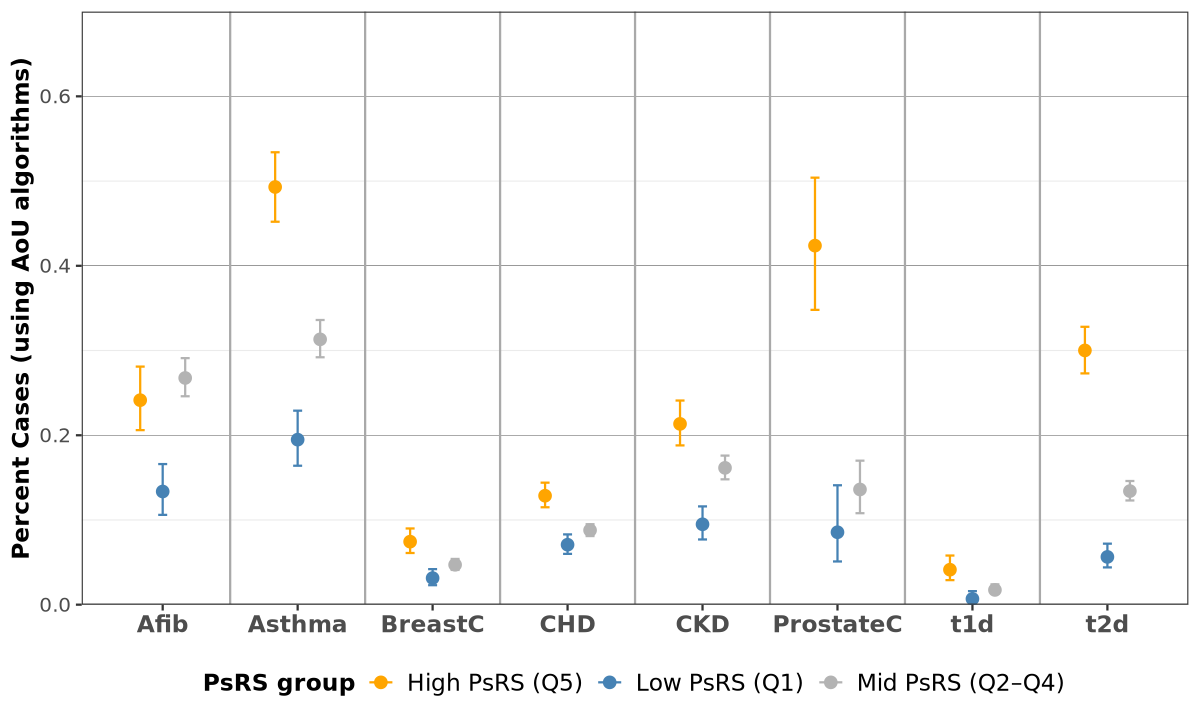

In [14]:
options(repr.plot.width = 10, repr.plot.height = 6)  # Set width and height

final_B_plot <- ggplot(plot_df, aes(
  x = disease,
  y = prevalence,
  color = PsRS_group
)) +
  geom_point(
    position = position_dodge(width = 0.5),
    size = 3
  ) +
  scale_y_continuous(
    limits = c(0, .70),
    expand = c(0, 0)
  ) +
  geom_errorbar(
    aes(ymin = lower, ymax = upper),
    position = position_dodge(width = 0.5),
    width = 0.2
  ) +
  scale_color_manual(
    values = c(
      "Low PsRS (Q1)" = "steelblue",   
      "Mid PsRS (Q2–Q4)" = "grey70", 
      "High PsRS (Q5)" = "orange"   
    )
  ) +
  theme(
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black"),
    axis.text.x = element_text(face="bold", size=14),
    axis.text.y = element_text(size=12),
    axis.title.y = element_text(face="bold", size=14),
    legend.title = element_text(face="bold", hjust = 0.5, size = 14),
    legend.text = element_text(size = 14),
    legend.position = "bottom",
    legend.box.spacing = unit(-5, "pt"),
  ) +
  labs(
    x = "",
    y = "Percent Cases (using AoU algorithms)",
    color = "PsRS group"
  ) +
  geom_vline(
    xintercept = seq(1.5, length(unique(plot_df$disease)) - 0.5, 1),
    color = "darkgrey"
  )


final_B_plot

## Low genetic and High PsRS vs High genetic and Low PsRS

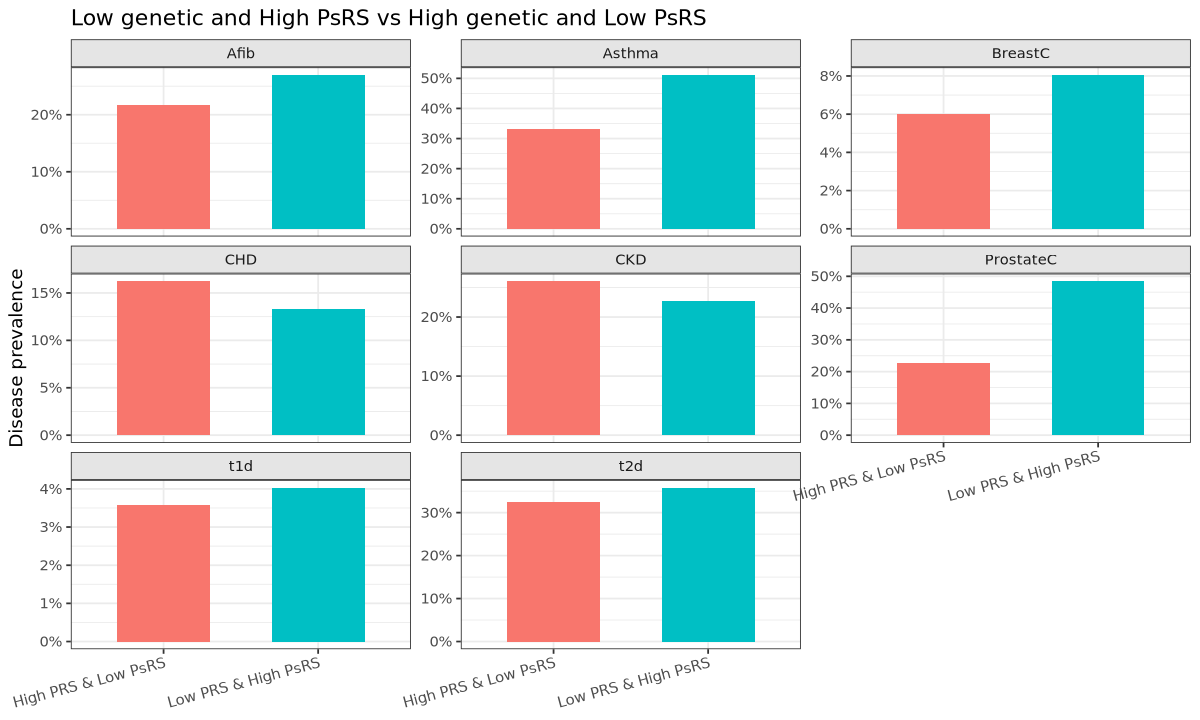

In [15]:
plot_df_2 <- map_dfr(diseases, function(disease) {

  q_col    <- paste0(disease, "_quantiles")
  psrs_col <- paste0(disease, "_PsRS")

  merged_data %>%
    mutate(PRS_q = ntile(.data[[q_col]], 5)) %>%
    mutate(PsRS_q = ntile(.data[[psrs_col]], 5)) %>%
    filter(PsRS_q == 1 & PRS_q == 5 | PsRS_q == 5 & PRS_q == 1) %>%
    group_by(PsRS_q, PRS_q) %>%
    summarise(
      prevalence = mean(.data[[disease]], na.rm = TRUE),
      .groups = "drop"
    ) %>%
    mutate(
      disease = disease,
      Group = case_when(
        PsRS_q == 5 & PRS_q == 1 ~ "Low PRS & High PsRS",
        PsRS_q == 1 & PRS_q == 5 ~ "High PRS & Low PsRS",
        TRUE ~ NA_character_
      )
    )
})

ggplot(plot_df_2, aes(x = Group, y = prevalence, fill = Group)) +
  geom_col(width = 0.6) +
  facet_wrap(~ disease, scales = "free_y") +
  scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  labs(
    x = NULL,
    y = "Disease prevalence",
    title = "Low genetic and High PsRS vs High genetic and Low PsRS"
  ) +
  theme_bw() +
  theme(
    legend.position = "none",
    strip.background = element_rect(fill = "grey90"),
    axis.text.x = element_text(angle = 15, hjust = 1)
  )

# Changes in Risk classification

In [16]:
generate_formulas <- function(disease) {
  covariates <- c("record_depth", "visit_frequency")
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")

  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_female")
  }

  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  PsRS  <- paste0(disease, "_PsRS")

  list(
    Genetic = as.formula(paste(disease, "~", paste(c(base, score), collapse = " + "))),
    Joint = as.formula(paste(disease, "~", paste(c(base, score, PsRS), collapse = " + ")))
  )
}

fit_and_predict <- function(disease, data) {

  # Generate formulas
  forms <- generate_formulas(disease)

  # Get all variables used in the models
  vars_in_model <- unique(c(all.vars(forms$Genetic), all.vars(forms$Joint)))

  # Keep only rows with no missing values in outcome or predictors
  filtered_data <- data %>%
    filter(!is.na(.data[[disease]])) %>%       # disease outcome must be non-NA
    filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

  # Fit models
  fit_genetic <- glm(forms$Genetic, family = binomial(), data = filtered_data)
  fit_joint   <- glm(forms$Joint,   family = binomial(), data = filtered_data)

  # Predict on the same filtered data
  filtered_data %>%
    mutate(
      Disease = disease,
      pred_genetic = predict(fit_genetic, newdata = filtered_data, type = "response"),
      pred_joint   = predict(fit_joint,   newdata = filtered_data, type = "response")
    )
}



flag_top10 <- function(df) {
  df %>%
    mutate(
      top_genetic = pred_genetic >= quantile(pred_genetic, 0.9, na.rm = TRUE),
      top_joint   = pred_joint   >= quantile(pred_joint,   0.9, na.rm = TRUE)
    )
}

flag_top05 <- function(df) {
  df %>%
    mutate(
      top_genetic = pred_genetic >= quantile(pred_genetic, 0.95, na.rm = TRUE),
      top_joint   = pred_joint   >= quantile(pred_joint,   0.95, na.rm = TRUE)
    )
}

compare_prevalence <- function(df, disease) {

  n_genetic_top <- sum(df$top_genetic)
  n_joint_top   <- sum(df$top_joint)
  overlap_top   <- sum(df$top_genetic & df$top_joint)

  # Number of people who changed top % classification
  changed <- (n_genetic_top - overlap_top) + (n_joint_top - overlap_top)
  total <- nrow(df)

  df %>%
    summarise(
      Disease = disease,
      prev_genetic_top = round(mean(.data[[disease]][top_genetic], na.rm = TRUE), 3),
      prev_joint_top   = round(mean(.data[[disease]][top_joint],   na.rm = TRUE), 3), 
      n_top_ten = n_genetic_top,
      overlap_top   = overlap_top,
      prop_maintained = round(overlap_top/n_genetic_top *100, 2), 
      prop_changed = 100- prop_maintained 
    ) %>%
    mutate(
      percent_diff_prev = round(100 * (prev_joint_top - prev_genetic_top) / prev_genetic_top, 2),
      percent_changed = round(100 * changed / total, 2)
    )
}


results <- map_dfr(diseases, function(disease) {

  fit_and_predict(disease, merged_data) %>%
    flag_top10() %>%
    compare_prevalence(disease)

})

results

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


Disease,prev_genetic_top,prev_joint_top,n_top_ten,overlap_top,prop_maintained,prop_changed,percent_diff_prev,percent_changed
<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,0.928,0.944,3032,2859,94.29,5.71,1.72,1.14
Afib,0.529,0.555,2591,1524,58.82,41.18,4.91,8.24
BreastC,0.169,0.190,6529,3644,55.81,44.19,12.43,8.84
CKD,0.597,0.607,4032,3367,83.51,16.49,1.68,3.30
CHD,0.450,0.448,9997,9159,91.62,8.38,-0.44,1.68
ProstateC,0.598,0.816,982,372,37.88,62.12,36.45,12.43
t2d,0.686,0.717,5320,3592,67.52,32.48,4.52,6.50
t1d,0.075,0.079,3655,2233,61.09,38.91,5.33,7.78


In [17]:
mean(results$prop_changed)
sd(results$prop_changed)

[1] 31.1825

[1] 19.53877

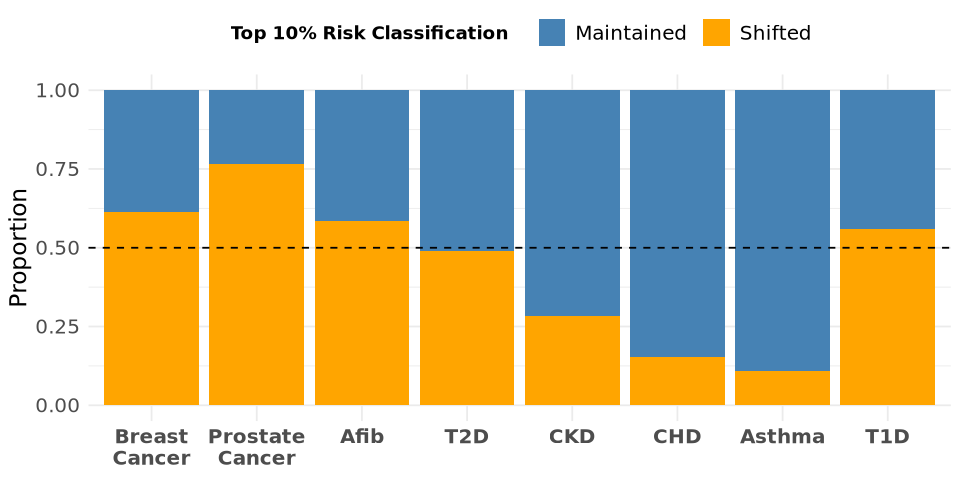

In [18]:
options(repr.plot.width = 8, repr.plot.height = 4)  # Set width and height

df_plot <- results %>%
  mutate(
    `Maintained ` = overlap_top,
    Shifted = (n_top_ten - overlap_top) * 2
  ) %>%
  select(Disease, `Maintained `, Shifted, percent_diff_prev)


df_long <- df_plot %>%
  pivot_longer(cols = c(`Maintained `, Shifted), names_to = "Status", values_to = "Count")

# Map names
df_long <- df_long  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping_short, 
                                                                     .default = Disease) )

facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

df_long <- df_long %>%
  mutate(
    Disease = factor(Disease, levels = facet_order)
  )


# Plot horizontal 100% stacked bar chart
plot_A <- ggplot(df_long, aes(x = Disease, y = Count, fill = Status)) +
  geom_bar(stat = "identity", position = "fill") +   # 100% stacked
  #coord_flip() +                                     # horizontal bars
  scale_fill_manual(values = c("Maintained " = "steelblue", "Shifted" = "orange")) +
  geom_hline(yintercept = 0.5, linetype = "dashed", color = "black") +  # dashed 50% line
  labs(
    x = NULL, 
    y = "Proportion",
    fill = "Top 10% Risk Classification   ",
    title = NULL
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(size=12, face= "bold"),
        axis.text.y = element_text(size=12),
        axis.title.y = element_text(size=14),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5),
                legend.text = element_text(size=12),
       legend.position = "top")

plot_A

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


Disease,prev_genetic_top,prev_joint_top,n_top_ten,overlap_top,prop_maintained,prop_changed,percent_diff_prev,percent_changed
<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,0.952,0.954,1516,1455,95.98,4.02,0.21,0.40
Afib,0.580,0.572,1296,690,53.24,46.76,-1.38,4.68
BreastC,0.187,0.222,3265,1812,55.50,44.50,18.72,4.45
CKD,0.661,0.668,2016,1728,85.71,14.29,1.06,1.43
CHD,0.518,0.517,4999,4651,93.04,6.96,-0.19,0.70
ProstateC,0.607,0.845,491,135,27.49,72.51,39.21,7.26
t2d,0.748,0.769,2660,1853,69.66,30.34,2.81,3.03
t1d,0.096,0.094,1828,1163,63.62,36.38,-2.08,3.64


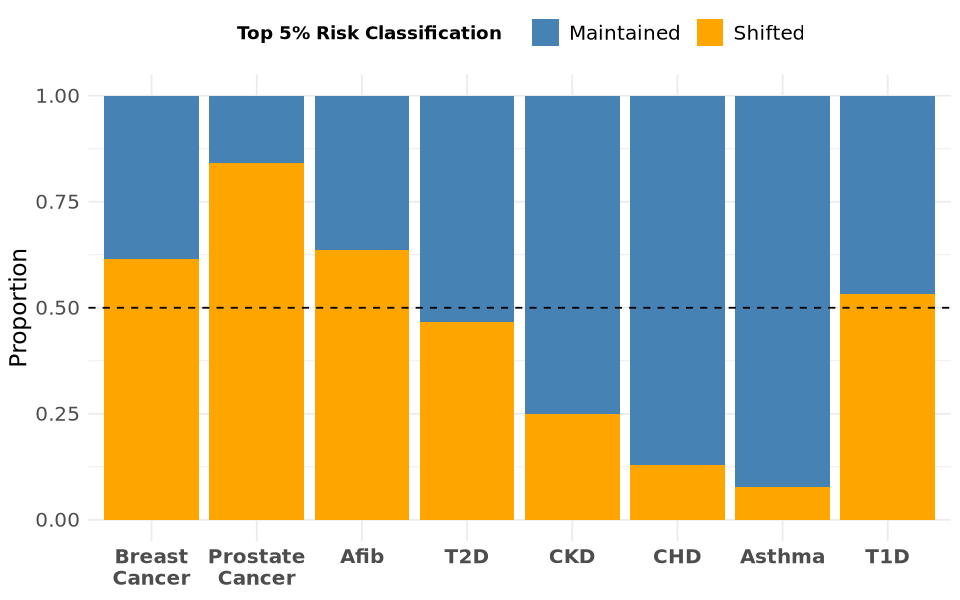

In [19]:
results2 <- map_dfr(diseases, function(disease) {

  fit_and_predict(disease, merged_data) %>%
    flag_top05() %>%
    compare_prevalence(disease)

})

results2 

df_plot <- results2 %>%
  mutate(
    `Maintained ` = overlap_top,
    Shifted = (n_top_ten - overlap_top) * 2
  ) %>%
  select(Disease, `Maintained `, Shifted, percent_diff_prev)


df_long <- df_plot %>%
  pivot_longer(cols = c(`Maintained `, Shifted), names_to = "Status", values_to = "Count")

# Map names
df_long <- df_long  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping_short, 
                                                                     .default = Disease) )

facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

df_long <- df_long %>%
  mutate(
    Disease = factor(Disease, levels = facet_order)
  )

options(repr.plot.width = 8, repr.plot.height = 5)  # Set width and height


# Plot horizontal 100% stacked bar chart
plot_B <- ggplot(df_long, aes(x = Disease, y = Count, fill = Status)) +
  geom_bar(stat = "identity", position = "fill") +   # 100% stacked
  #coord_flip() +                                     # horizontal bars
  scale_fill_manual(values = c("Maintained " = "steelblue", "Shifted" = "orange")) +
  geom_hline(yintercept = 0.5, linetype = "dashed", color = "black") +  # dashed 50% line
  labs(
    x = NULL, 
    y = "Proportion",
    fill = "Top 5% Risk Classification   ",
    title = NULL
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(size=12, face= "bold"),
        axis.text.y = element_text(size=12),
        axis.title.y = element_text(size=14),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5),
                legend.text = element_text(size=12),
       legend.position = "top")

plot_B

In [20]:
mean(results2$prop_changed)
sd(results2$prop_changed)

[1] 31.97

[1] 23.17827


Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




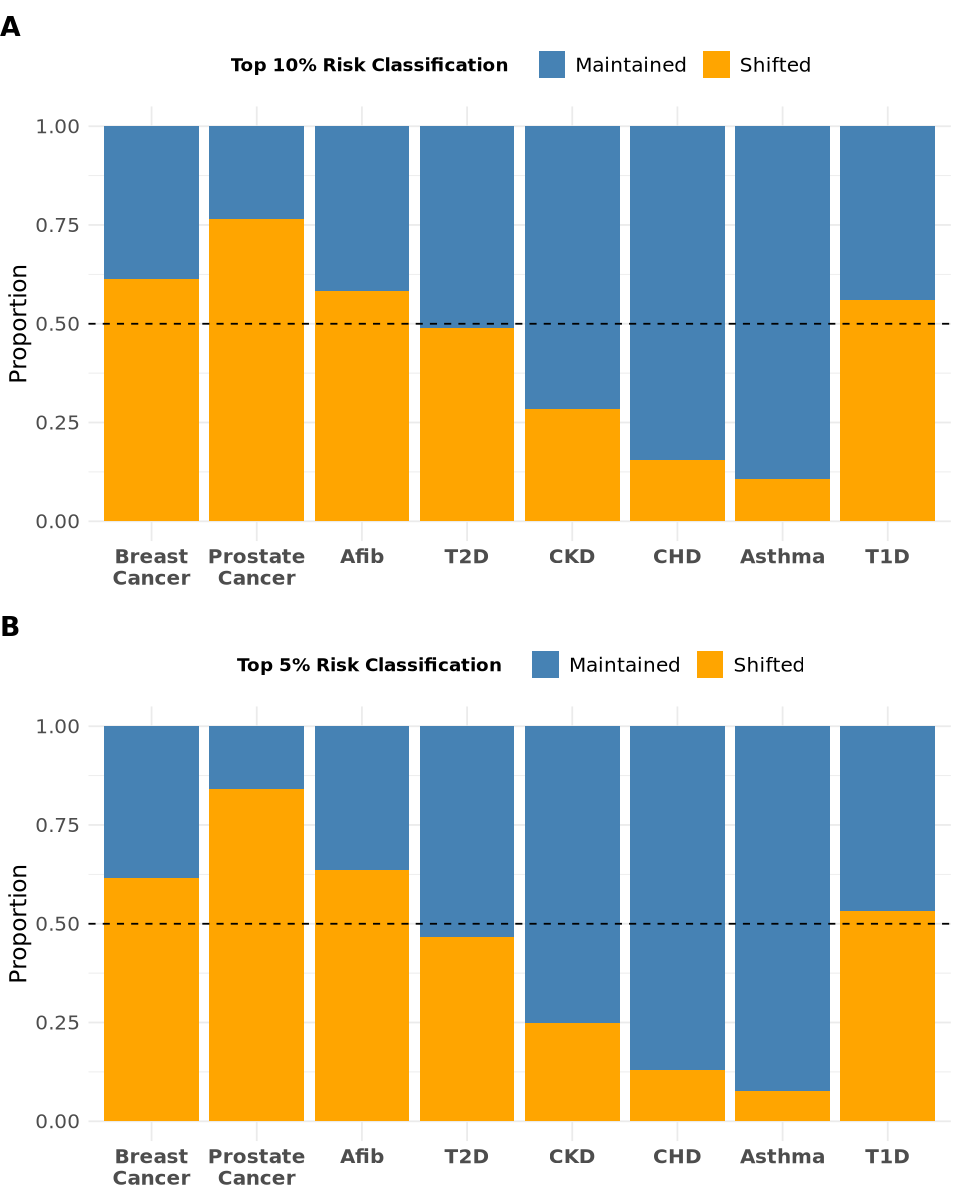

In [21]:
#AB Plot 
library(gridExtra)
library(grid)

options(repr.plot.width = 8, repr.plot.height = 10)  # Set width and height

grid.arrange(
  arrangeGrob(
    plot_A,
    top = textGrob("A", x = unit(0, "npc"), just = c("left", "top"),
                   gp = gpar(fontsize = 16, fontface = "bold"))
  ),
  arrangeGrob(
    plot_B, 
    top = textGrob("B", x = unit(0, "npc"), just = c("left", "top"),
                   gp = gpar(fontsize = 16, fontface = "bold"))
  ),
  ncol = 1
)